In [1]:
!pip install pyproj

In [2]:
!pip install geopandas

In [3]:
!pip uninstall cython -y
!pip install cython
!pip uninstall cartopy -y
!pip install cartopy

Found existing installation: Cython 3.0.2
Uninstalling Cython-3.0.2:
  Successfully uninstalled Cython-3.0.2
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 12.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 29.2 MB/s eta 0:00:00


In [4]:
!apt-get -qq install python-cartopy python3-cartopy
!pip uninstall -y shapely    # cartopy and shapely aren't friends (early 2020)
!pip install shapely --no-binary shapely

E: Unable to locate package python-cartopy
Found existing installation: shapely 2.0.1
Uninstalling shapely-2.0.1:
  Successfully uninstalled shapely-2.0.1
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.5/275.5 kB 4.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for shapely: filename=shapely-2.0.1-cp310-cp310-linux_x86_64.whl size=890037 sha256=871f9cedfd061ef8ddf8108ed874a432e49cab7db7b202eb90577815ccbc6dd9
  Stored in directory: /root/.cache/pip/wheels/07/bd/06/4e979fa263bca266484ee65f5aab8e6b1c9b20f8caa6f2d7da
Successfully built shapely


In [5]:
import pandas as pd
import pyproj
import math
import matplotlib.pyplot as plt
import seaborn as sb
import urllib.request

%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import cm

import numpy as np

import cartopy
import cartopy.crs as ccrs                   # for projections
import cartopy.feature as cfeature           # for features
import cartopy.io.shapereader as shapereader
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from cartopy.feature.nightshade import Nightshade
import geopandas as gpd
import random
from shapely.geometry import Point, Polygon
import time

In [6]:
ruta = 'https://raw.githubusercontent.com/fmoreno4/cd-files/main/eventos_dengue_2020.csv'
#ruta = 'https://raw.githubusercontent.com/rasief/cartografia/master/melb_data.csv'
df = pd.read_csv(ruta)
df

,ID,fec_not,semana,año,edad_,uni_med_,sexo_,cod_pais_o,cod_dpto_o,cod_mun_o,...,hipotension,hepatomegalia,hemorragia_mucosa,hipotermia,caida_plaquetas,acum_liquido,aum_hematocrito,conducta,latitud,longitud
0,1,17/01/2020,1,2020,25,1,F,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.076011,-73.102501
1,2,10/01/2020,1,2020,24,1,M,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.079495,-73.105400
2,3,12/01/2020,1,2020,58,1,M,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.090290,-73.091003
3,4,12/01/2020,1,2020,29,1,F,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.067435,-73.090958
4,5,10/01/2020,1,2020,56,1,F,170,68,276,...,2,2,2,2,1,2,2,2. Hospitalizacion piso,7.066905,-73.104980
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257,1258,7/03/2020,9,2020,36,1,F,170,68,276,...,2,2,1,2,2,2,2,1. Ambulatorio,7.072610,-73.099487
1258,1259,13/03/2020,9,2020,42,1,M,170,68,276,...,2,2,2,2,1,2,1,2. Hospitalizacion piso,7.065252,-73.103607
1259,1260,8/03/2020,9,2020,2,1,M,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.091391,-73.103264
1260,1261,11/03/2020,9,2020,12,1,F,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.061083,-73.097000


In [7]:
#Creación de la proyección
P = pyproj.Proj(proj='utm', zone=18, ellps='WGS84', preserve_units=True)

In [8]:
#Se convertirán las coordenadas geográficas a UTM
df['x'], df['y'] = P(df['longitud'], df['latitud'])
df

,ID,fec_not,semana,año,edad_,uni_med_,sexo_,cod_pais_o,cod_dpto_o,cod_mun_o,...,hemorragia_mucosa,hipotermia,caida_plaquetas,acum_liquido,aum_hematocrito,conducta,latitud,longitud,x,y
0,1,17/01/2020,1,2020,25,1,F,170,68,276,...,2,2,2,2,2,1. Ambulatorio,7.076011,-73.102501,709584.027559,782579.281866
1,2,10/01/2020,1,2020,24,1,M,170,68,276,...,2,2,2,2,2,1. Ambulatorio,7.079495,-73.105400,709262.121378,782963.354103
2,3,12/01/2020,1,2020,58,1,M,170,68,276,...,2,2,2,2,2,1. Ambulatorio,7.090290,-73.091003,710847.924654,784163.825097
3,4,12/01/2020,1,2020,29,1,F,170,68,276,...,2,2,2,2,2,1. Ambulatorio,7.067435,-73.090958,710863.366771,781635.895608
4,5,10/01/2020,1,2020,56,1,F,170,68,276,...,2,2,1,2,2,2. Hospitalizacion piso,7.066905,-73.104980,709314.159319,781570.969374
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257,1258,7/03/2020,9,2020,36,1,F,170,68,276,...,1,2,2,2,2,1. Ambulatorio,7.072610,-73.099487,709918.546763,782204.438977
1258,1259,13/03/2020,9,2020,42,1,M,170,68,276,...,2,2,1,2,1,2. Hospitalizacion piso,7.065252,-73.103607,709466.644754,781388.734012
1259,1260,8/03/2020,9,2020,2,1,M,170,68,276,...,2,2,2,2,2,1. Ambulatorio,7.091391,-73.103264,709492.782783,784279.996264
1260,1261,11/03/2020,9,2020,12,1,F,170,68,276,...,2,2,2,2,2,1. Ambulatorio,7.061083,-73.097000,710198.574916,780930.648555


In [9]:
columnas_deseadas=['x', 'y']
df_original= df[columnas_deseadas].copy()
df_original

,x,y
0,709584.027559,782579.281866
1,709262.121378,782963.354103
2,710847.924654,784163.825097
3,710863.366771,781635.895608
4,709314.159319,781570.969374
...,...,...
1257,709918.546763,782204.438977
1258,709466.644754,781388.734012
1259,709492.782783,784279.996264
1260,710198.574916,780930.648555


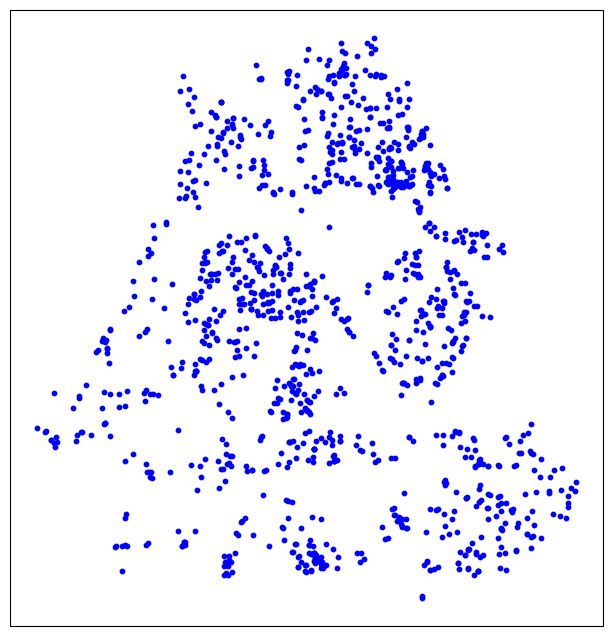

In [10]:
subplot_kw = dict(projection=ccrs.PlateCarree())

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=subplot_kw)

ax.scatter(df['longitud'], df['latitud'], zorder=10, c='b', s=10)
#ax.scatter(df['Longtitude'], df['Lattitude'], zorder=10, c='b', s=10)
plt.show()

In [11]:
#Se carga la cartografía de Floridablanca/Melbourne
url = 'https://raw.githubusercontent.com/fmoreno4/cd-files/main/'

file_list = ["68276_urbano.cpg", "68276_urbano.dbf", "68276_urbano.prj", "68276_urbano.shp", "68276_urbano.shx"]

for file in file_list:
    urllib.request.urlretrieve(url+file, file)

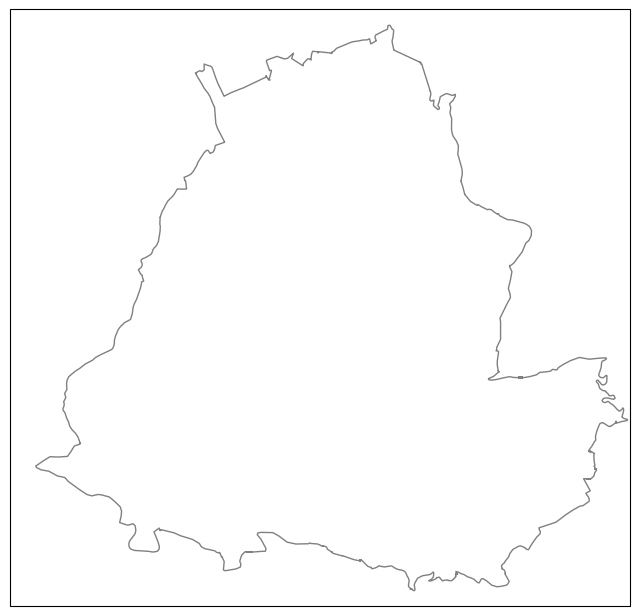

In [12]:
subplot_kw = dict(projection=ccrs.PlateCarree())

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=subplot_kw)

# Puntos Floridablanca
lower_lon = -73.1215
upper_lon = -73.0732
lower_lat = 7.054
upper_lat = 7.1005

ax.set_extent([lower_lon, upper_lon, lower_lat, upper_lat])

reader = shapereader.Reader('68276_urbano.shp')

for poli in reader.geometries():
    ax.add_geometries([poli], ccrs.PlateCarree(), facecolor='white', edgecolor='gray')

plt.show()

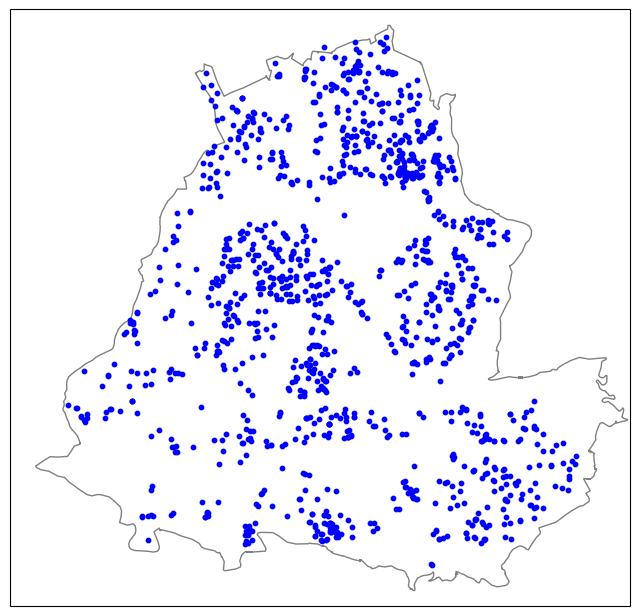

In [13]:
subplot_kw = dict(projection=ccrs.PlateCarree())

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=subplot_kw)

# Puntos Floridablanca
lower_lon = -73.1215
upper_lon = -73.0732
lower_lat = 7.054
upper_lat = 7.1005

ax.set_extent([lower_lon, upper_lon, lower_lat, upper_lat])

reader = shapereader.Reader('68276_urbano.shp')

for poli in reader.geometries():
    ax.add_geometries([poli], ccrs.PlateCarree(), facecolor='white', edgecolor='gray')

ax.scatter(df['longitud'], df['latitud'], zorder=10, c='b', s=10)

plt.show()

In [14]:
import geopandas as gpd

# Cargar el shapefile en un DataFrame de GeoPandas
gdf = gpd.read_file('68276_urbano.shp')

# Calcular el área en metros cuadrados para cada geometría en Plate Carrée y agregarlo como una nueva columna
gdf = gdf.to_crs({'init': 'epsg:32663'})  # Plate Carrée (EPSG:32663)
gdf['area_m2'] = gdf['geometry'].area

# Sumar todas las áreas para obtener el área total en metros cuadrados
area_total_m2 = gdf['area_m2'].sum()

print("Área total en metros cuadrados (Plate Carrée):", area_total_m2)

Área total en metros cuadrados (Plate Carrée): 14378860.411779443


/usr/local/lib/python3.10/dist-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


In [15]:
def dist_puntos(p1, p2):
  return ((p1[0]-p2[0])**2 + (p1[1]-p2[1])**2)**0.5

In [16]:
import numpy as np
from scipy.spatial import cKDTree

# Datos de puntos
points = np.column_stack((df['x'], df['y']))
#points = list(zip(df['x'], df['y']))

def funcion_k(points, max_dist, area):
  num_points = len(points)

  count = 0
  for i in range(num_points):
    for j in range(i+1, num_points):
      if dist_puntos(points[i], points[j]) <= max_dist:
        count += 1

  k = area * count / num_points**2

  return k

valor_k = funcion_k(points, 100, area_total_m2)
valor_k

35914.55888325239

In [17]:
poligono = gpd.read_file("68276_urbano.shp")
crs = poligono.crs
crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

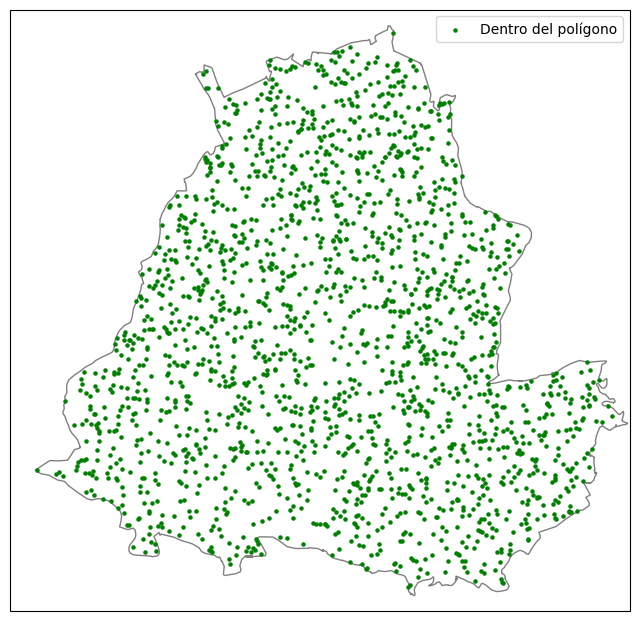

In [18]:
import random
import matplotlib.pyplot as plt
import shapely.geometry as sg
from shapely.geometry import Point
import geopandas as gpd
import cartopy.crs as ccrs

# Definir el contexto de proyección
subplot_kw = dict(projection=ccrs.PlateCarree())
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=subplot_kw)

# Definir los límites geográficos
lower_lon = -73.1215
upper_lon = -73.0732
lower_lat = 7.054
upper_lat = 7.1005

# Configurar los límites del mapa
ax.set_extent([lower_lon, upper_lon, lower_lat, upper_lat])

# Cargar el shapefile que contiene el polígono irregular
gdf = gpd.read_file('68276_urbano.shp')

# Obtener el polígono a partir del shapefile
polygon = gdf.geometry.iloc[0]

# Generar puntos aleatorios dentro del polígono hasta alcanzar el número deseado
points_inside = []
num_points = 1962

while len(points_inside) < num_points:
    x = random.uniform(lower_lon, upper_lon)
    y = random.uniform(lower_lat, upper_lat)
    point = Point(x, y)
    if point.within(polygon):
        points_inside.append(point)

# Dibujar el polígono
gdf.plot(ax=ax, color='white', edgecolor='gray')

# Dibujar los puntos dentro del polígono
x_inside, y_inside = zip(*[(point.x, point.y) for point in points_inside])
ax.scatter(x_inside, y_inside, color='green', s=5, label='Dentro del polígono')

# Mostrar el mapa con el polígono y los puntos
ax.legend()
plt.show()

# Imprimir las coordenadas de los puntos dentro del polígono
#print("\nCoordenadas de los puntos dentro del polígono:")
#for point in points_inside:
#    print(f'({point.x}, {point.y})')

In [19]:
import numpy as np
import geopandas as gpd
import shapely.geometry
import pandas as pd


n_puntos = 1262
num_mapas = 9
mapas_de_puntos = []
coordenadas_proyectadas = []

for grupo in range(1, num_mapas + 1):
    puntos_a = []

    for _ in range(n_puntos):
        while True:
            punto_x = np.random.uniform(poligono.bounds.minx, poligono.bounds.maxx)
            punto_y = np.random.uniform(poligono.bounds.miny, poligono.bounds.maxy)
            punto = shapely.geometry.Point(punto_x, punto_y)

            if poligono.geometry.contains(punto).any():
                coordenadas_proyectadas.append(P(punto_x[0], punto_y[0]))  # Guardar coordenadas cartesianas
                break

# Crear el DataFrame con coordenadas_proyectadas y la columna 'Grupo'
df = pd.DataFrame(coordenadas_proyectadas, columns=['x', 'y'])
df['Grupo'] = np.repeat(np.arange(1, num_mapas + 1), n_puntos)

# Crear 9 DataFrames distintos, uno para cada grupo
dataframes_por_grupo = {}  # Un diccionario para almacenar los DataFrames por grupo

for grupo_numero, grupo_datos in df.groupby('Grupo'):
    dataframes_por_grupo[f'df_grupo{grupo_numero}'] = grupo_datos.copy()

# Ahora hay un diccionario llamado dataframes_por_grupo con 9 DataFrames distintos, uno para cada grupo.
# Se puede acceder a cada DataFrame utilizando dataframes_por_grupo['df_grupoX'], donde X es el número de grupo.

In [20]:
def eliminar_columna_por_grupo(dataframes_por_grupo):
    for grupo_numero in range(1, 10):
        columna_grupo = f'df_grupo{grupo_numero}'
        if columna_grupo in dataframes_por_grupo:
            dataframes_por_grupo[columna_grupo] = dataframes_por_grupo[columna_grupo].drop('Grupo', axis=1)
    return dataframes_por_grupo

# Llama a la función para realizar la operación
dataframes_por_grupo = eliminar_columna_por_grupo(dataframes_por_grupo)

In [21]:
dataframes_por_grupo['df_grupo9']

,x,y
10096,710570.396975,782462.833929
10097,711632.049689,783173.093357
10098,711948.452674,782073.288167
10099,709462.373962,781460.597122
10100,709708.512281,782781.080927
...,...,...
11353,711371.885407,780896.348084
11354,710356.731992,783002.646941
11355,710509.599034,784527.156941
11356,712226.961647,781810.755998


In [22]:
df_grupo1 = dataframes_por_grupo['df_grupo1']
df_grupo2 = dataframes_por_grupo['df_grupo2']
df_grupo3 = dataframes_por_grupo['df_grupo3']
df_grupo4 = dataframes_por_grupo['df_grupo4']
df_grupo5 = dataframes_por_grupo['df_grupo5']
df_grupo6 = dataframes_por_grupo['df_grupo6']
df_grupo7 = dataframes_por_grupo['df_grupo7']
df_grupo8 = dataframes_por_grupo['df_grupo8']
df_grupo9 = dataframes_por_grupo['df_grupo9']

In [23]:
df_grupo1

,x,y
0,709983.254707,784615.906230
1,711121.476207,782569.280596
2,710766.983382,782874.192910
3,711011.240342,780859.417115
4,709765.574096,784149.094970
...,...,...
1257,711460.415672,781173.774792
1258,708701.575636,780715.683214
1259,711209.170435,784532.580643
1260,711023.648557,782709.957706


In [24]:
df_original

,x,y
0,709584.027559,782579.281866
1,709262.121378,782963.354103
2,710847.924654,784163.825097
3,710863.366771,781635.895608
4,709314.159319,781570.969374
...,...,...
1257,709918.546763,782204.438977
1258,709466.644754,781388.734012
1259,709492.782783,784279.996264
1260,710198.574916,780930.648555


In [25]:
print("DataFrame original")
points = np.column_stack((df_original['x'], df_original['y']))
valori_original = funcion_k(points,100,area_total_m2)
print(valori_original)
for i in range(1, 10):
    nombre_df = f'df_grupo{i}'

    dataframe_actual = globals()[nombre_df]
    print("DataFrame",i)
    pointsi = np.column_stack((dataframe_actual['x'], dataframe_actual['y']))
    valorik= funcion_k(pointsi, 100, area_total_m2)
    print(valorik)


DataFrame original
35914.55888325239
DataFrame 1
15348.102086859995
DataFrame 2
15546.724584454656
DataFrame 3
15510.61140307381
DataFrame 4
15420.328449621693
DataFrame 5
15023.083454432373
DataFrame 6
15483.526517038174
DataFrame 7
15808.545149465795
DataFrame 8
15158.50788461055
DataFrame 9
16196.761849309902


In [26]:
dataframes = {
    'df_original': df_original,
    'df_grupo1': df_grupo1,
    'df_grupo2': df_grupo2,
    'df_grupo3': df_grupo3,
    'df_grupo4': df_grupo4,
    'df_grupo5': df_grupo5,
    'df_grupo6': df_grupo6,
    'df_grupo7': df_grupo7,
    'df_grupo8': df_grupo8,
    'df_grupo9': df_grupo9
}

resultados = {'grupo': [], 'distancia_20': [], 'distancia_40': [], 'distancia_60': [], 'distancia_80': [], 'distancia_100': [], 'distancia_120': [], 'distancia_140': [], 'distancia_160': [], 'distancia_180': [], 'distancia_200': []}

for nombre_df, dataframe in dataframes.items():
    resultados['grupo'].append(nombre_df)
    for metros in range(20, 201, 20):
        dataframe_actual = globals()[nombre_df]
        pointsi = np.column_stack((dataframe_actual['x'], dataframe_actual['y']))
        resultado = funcion_k(pointsi, metros, area_total_m2)
        resultados[f'distancia_{metros}'].append(resultado)

df_resultados = pd.DataFrame(resultados)

In [27]:
df_resultados

,grupo,distancia_20,distancia_40,distancia_60,distancia_80,distancia_100,distancia_120,distancia_140,distancia_160,distancia_180,distancia_200
0,df_original,3683.544501,8730.361599,16386.356052,25730.641734,35914.558883,47813.852148,61807.709933,77417.632585,93090.753304,110650.787751
1,df_grupo1,686.150446,2518.894401,5462.118684,9714.445791,15348.102087,21821.389849,29450.299416,38298.028854,48518.059185,59514.522916
2,df_grupo2,541.697721,2374.441676,5552.401637,9922.096584,15546.724584,21992.927461,29603.780437,38713.330440,49294.492585,60724.314492
3,df_grupo3,650.037265,2672.375422,5669.769477,9976.266356,15510.611403,22489.483705,30768.430536,39778.669291,49727.850761,60823.625741
4,df_grupo4,677.122151,2564.035878,5723.939249,9876.955108,15420.328450,21920.701098,29513.497483,38135.519538,48174.983962,59252.702351
5,df_grupo5,541.697721,2464.724629,5435.033798,9642.219429,15023.083454,22038.068938,29928.799069,39598.103384,49493.115082,60453.465632
6,df_grupo6,641.008970,2636.262241,5796.165612,9876.955108,15483.526517,22173.493368,29694.063390,38713.330440,48536.115776,59478.409734
7,df_grupo7,650.037265,2455.696334,5651.712886,10382.539647,15808.545149,22661.021316,30741.345650,39887.008835,49935.501554,61428.521529
8,df_grupo8,641.008970,2401.526562,5642.684591,9976.266356,15158.507885,21631.795647,29513.497483,38559.849419,49258.379403,61311.153689
9,df_grupo9,631.980674,2654.318831,5796.165612,10391.567942,16196.761849,22525.596886,30425.355313,39209.886684,49195.181336,60281.928020


In [28]:
fila_df_original = df_resultados[df_resultados['grupo'] == 'df_original']
percentiles_2_5 = df_resultados.filter(like='distancia_').quantile(0.025)
percentiles_97_5 = df_resultados.filter(like='distancia_').quantile(0.975)

df_final = pd.DataFrame({
    'distancia': [int(col.split('_')[-1]) for col in percentiles_2_5.index],
    'percentil_2.5': percentiles_2_5.values,
    'percentil_97.5': percentiles_97_5.values,
    'K': fila_df_original.iloc[:, 1:].values.flatten()
})

df_final = df_final.sort_values(by='distancia')

df_final

,distancia,percentil_2.5,percentil_97.5,K
0,20,541.697721,3009.130839,3683.544501
1,40,2380.535775,7367.314709,8730.361599
2,60,5441.127897,14003.563203,16386.356052
3,80,9658.470360,22279.350131,25730.641734
4,100,15053.553951,31478.054551,35914.558883
5,120,21674.454343,42154.465211,47813.852148
6,140,29464.518981,54823.872069,61807.709933
7,160,38172.084134,68973.242241,77417.632585
8,180,48252.175887,83380.821661,93090.753304
9,200,59303.486512,99575.777851,110650.787751


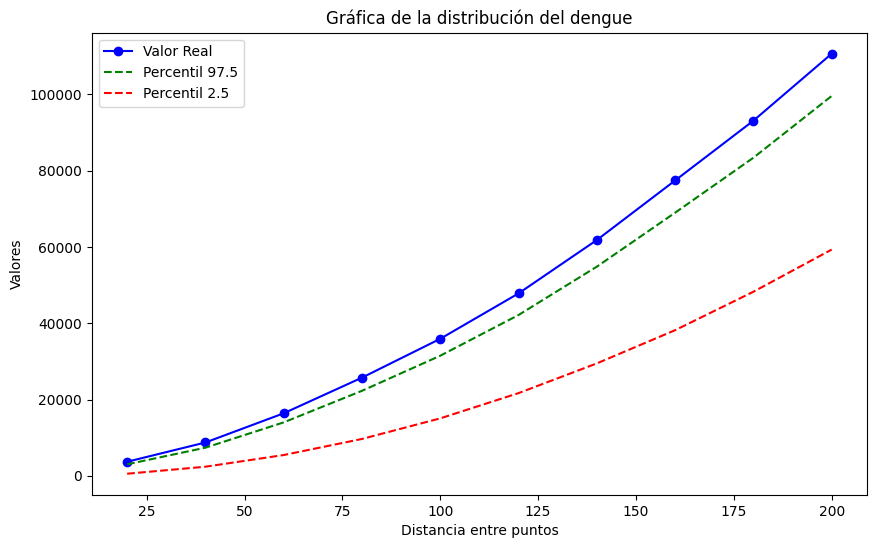

In [29]:
plt.figure(figsize=(10, 6))
plt.plot(df_final['distancia'], df_final['K'], label='Valor Real', color='blue', marker='o')
plt.plot(df_final['distancia'], df_final['percentil_97.5'], label='Percentil 97.5', color='green', linestyle='--')
plt.plot(df_final['distancia'], df_final['percentil_2.5'], label='Percentil 2.5', color='red', linestyle='--')

plt.xlabel('Distancia entre puntos')
plt.ylabel('Valores')
plt.title('Gráfica de la distribución del dengue')
plt.legend()

plt.show()